# 02. Gaussian Naive Bayes: Variables Continuas, Geometría de Fronteras y Transformaciones

**Módulo:** `05_Naive_Bayes`  
**Objetivo:** Dominar la formulación matemática, geométrica y computacional de *Gaussian Naive Bayes* (GNB) para espacios continuos $\mathbb{R}^D$, humanizar y deducir analíticamente los estimadores de Máxima Verosimilitud (MLE), comprender por qué su matriz de covarianza diagonal induce fronteras de decisión cuadráticas alineadas a los ejes, desmitificar la función dual del hiperparámetro `var_smoothing`, corregir violaciones severas al supuesto de normalidad (asimetría y multimodalidad) mediante `PowerTransformer(method='yeo-johnson')` y demostrar la invarianza del modelo frente al escalamiento lineal.

---

## 1. Formulación Matemática y Perspectiva Geométrica de Gaussian Naive Bayes

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En el Notebook 01 aprendimos a clasificar contando frecuencias discretas (ej. si el ingreso es *Bajo, Medio o Alto*). Pero, ¿qué ocurre cuando nuestras características son **variables continuas de punto flotante** como el monto exacto de una transferencia ($\$14,523.87$), la temperatura de una turbina ($742.5^\circ\text{C}$) o la concentración química de fenoles en un vino ($2.84\text{ mg/L}$)?
* En un espacio continuo, la probabilidad de que dos clientes tengan *exactamente* el mismo monto al centavo es prácticamente cero; una tabla de frecuencias tendría casi todas sus celdas vacías.
* Cortar las variables en intervalos arbitrarios (*binning* o discretización) destruye la resolución numérica e introduce fronteras artificiales.
* Por otro lado, si intentáramos ajustar una campana Gaussiana multivariada completa en un problema con $D = 1,000$ sensores, tendríamos que estimar e invertir una matriz de covarianza de $1,000 \times 1,000$ ($500,500$ parámetros por clase), la cual sería singular (no invertible) si tenemos menos de $1,000$ muestras.

**¿Cómo modela `GaussianNB` variables continuas de forma instantánea y sin invertir matrices?** Asumiendo que cada característica continua actúa como una campana Gaussiana unidimensional independiente dentro de cada clase, lo que geométricamente equivale a dibujar **elipses de probabilidad cuyos ejes están estrictamente alineados con los ejes coordenados**.

---

### Paso 2: Formalismo Matemático Riguroso

Cuando las características de entrada son continuas, $\mathbf{x} = (x_1, x_2, \dots, x_D)^\top \in \mathbb{R}^D$, **Gaussian Naive Bayes** asume que, condicionada a la clase $Y = c_k$, cada característica continua $X_j$ sigue una **distribución normal (Gaussiana) univariada**:

$$X_j \mid (Y = c_k) \sim \mathcal{N}\left(\mu_{kj}, \sigma_{kj}^2\right)$$

**Definición explícita de notación:**
* $k \in \{1, \dots, C\}$: Subíndice de la clase $c_k$.
* $j \in \{1, \dots, D\}$: Subíndice de la característica continua $X_j$.
* $\mu_{kj} = \mathbb{E}[X_j \mid Y = c_k] \in \mathbb{R}$: Media poblacional (centro de masa) de la característica $j$ dentro de la clase $c_k$.
* $\sigma_{kj}^2 = \text{Var}(X_j \mid Y = c_k) > 0$: Varianza condicional (dispersión cuadrática) de la característica $j$ dentro de la clase $c_k$.

La función de densidad de probabilidad (*PDF*) para la $j$-ésima característica en la clase $c_k$ está dada por:

$$p(x_j \mid Y = c_k) = \frac{1}{\sqrt{2\pi\sigma_{kj}^2}} \exp\left( -\frac{(x_j - \mu_{kj})^2}{2\sigma_{kj}^2} \right)$$

#### Perspectiva Multivariada: Matriz de Covarianza Diagonal
Bajo el supuesto "ingenuo" de independencia condicional ($X_i \perp\!\!\!\perp X_j \mid Y$), la densidad conjunta condicional es el producto de las $D$ densidades univariadas. Algebraicamente, esto equivale exactamente a modelar cada clase mediante una **Distribución Normal Multivariada** $\mathcal{N}(\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$ cuya matriz de covarianza $\boldsymbol{\Sigma}_k \in \mathbb{R}^{D \times D}$ está restringida a ser **estrictamente diagonal** (todas las covarianzas cruzadas fuera de la diagonal son cero: $\text{Cov}(X_i, X_j \mid Y=c_k) = 0 \; \forall i \neq j$):

$$\boldsymbol{\Sigma}_k = \text{diag}\left(\sigma_{k1}^2, \sigma_{k2}^2, \dots, \sigma_{kD}^2\right) = \begin{pmatrix} \sigma_{k1}^2 & 0 & \cdots & 0 \\ 0 & \sigma_{k2}^2 & \cdots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \cdots & \sigma_{kD}^2 \end{pmatrix}$$

Dado que $\det(\boldsymbol{\Sigma}_k) = \prod_{j=1}^D \sigma_{kj}^2$ y $\boldsymbol{\Sigma}_k^{-1} = \text{diag}(1/\sigma_{k1}^2, \dots, 1/\sigma_{kD}^2)$, la distancia de Mahalanobis cuadrática $(\mathbf{x} - \boldsymbol{\mu}_k)^\top \boldsymbol{\Sigma}_k^{-1} (\mathbf{x} - \boldsymbol{\mu}_k)$ se desacopla en la suma de distancias univariadas estandarizadas $\sum_{j=1}^D \frac{(x_j - \mu_{kj})^2}{\sigma_{kj}^2}$.

#### Regla de Decisión MAP en Espacio Logarítmico
Sustituyendo la densidad Gaussiana en la función discriminante logarítmica $\ell_k(\mathbf{x}) = \ln P(Y = c_k) + \sum_{j=1}^{D} \ln p(x_j \mid Y = c_k)$, obtenemos la expresión exacta que evalúa Scikit-Learn internamente (`_joint_log_likelihood`):

$$\ell_k(\mathbf{x}) = \ln P(Y = c_k) - \frac{1}{2} \sum_{j=1}^{D} \ln\left(2\pi\sigma_{kj}^2\right) - \frac{1}{2} \sum_{j=1}^{D} \frac{(x_j - \mu_{kj})^2}{\sigma_{kj}^2}$$

---

### Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Término en $\ell_k(\mathbf{x})$ | ¿Qué mide física y geométricamente? | ¿De dónde sale en los datos? | ¿Qué pasa en casos límite ($0$ o $\infty$)? |
| :--- | :--- | :--- | :--- |
| $\ln P(Y = c_k)$ | **Ventaja inicial (*Log-Prior*):** Punto de partida de la clase antes de mirar los sensores. | $\ln(N_k / N)$. | Si una clase es rarísima ($P \to 0$), arranca con una penalización negativa enorme. |
| $-\frac{1}{2}\sum_{j=1}^D \ln(2\pi\sigma_{kj}^2)$ | **Penalización por Dispersión (Complejidad Volumétrica):** Castiga a las clases que tienen campanas muy anchas y difusas. | De la anchura $\sigma_{kj}^2$ de cada característica en la clase $c_k$. | Si $\sigma_{kj}^2 \to 0$, este término explota hacia $+\infty$ ($\ln(0) = -\infty$), requiriendo `var_smoothing`. |
| $-\frac{1}{2}\sum_{j=1}^D \frac{(x_j - \mu_{kj})^2}{\sigma_{kj}^2}$ | **Penalización por Distancia al Centro (*Z-score* al cuadrado):** Cuántas desviaciones estándar se aleja el punto $x_j$ del centro $\mu_{kj}$ de la clase. | Del promedio $\mu_{kj}$ y varianza $\sigma_{kj}^2$ de la clase $c_k$. | Si $x_j = \mu_{kj}$ (encaje perfecto en el centro), la penalización es $0$. Si $\sigma_{kj}^2 \to 0$ y $x_j \neq \mu_{kj}$, produce división por cero (`-inf` / `NaN`). |

In [6]:
# Configuración del entorno y librerías estándar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_wine, make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, f1_score, brier_score_loss, classification_report

# Estándar visual del repositorio
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


---

## 2. Estimación de Parámetros por Máxima Verosimilitud (MLE) e Inspección en Scikit-Learn

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Motivación Antes de Derivar)
Cuando ejecutamos `gnb.fit(X_train, y_train)`, el algoritmo recibe una nube de puntos continuos para cada clase, pero desconoce dónde está el verdadero centro ni qué tan ancha es la campana Gaussiana que los generó.  
**¿Qué hace filosóficamente el método de Máxima Verosimilitud (MLE) antes de escribir una sola derivada?**  
Imagina que tienes una linterna con foco ajustable (donde el lugar al que apuntas es $\mu_{kj}$ y la apertura del haz de luz es $\sigma_{kj}$). **Buscamos el centro de masa y la dispersión que maximicen la probabilidad conjunta de haber observado exactamente nuestra muestra histórica.** Si apuntamos lejos de los datos, la verosimilitud cae a cero; si hacemos el haz demasiado estrecho, dejamos puntos en la oscuridad; si lo hacemos demasiado ancho, la intensidad de luz se diluye. El cálculo diferencial simplemente encuentra el punto exacto de equilibrio.

---

### 📐 Paso 2: Formalismo Matemático Riguroso (Deducción Analítica de MLE)

¿De dónde salen analíticamente los valores $\hat{\mu}_{kj}$ y $\hat{\sigma}_{kj}^2$ durante `.fit(X, y)`? Se obtienen maximizando la función de log-verosimilitud sobre el subconjunto de muestras $\mathcal{D}_k = \{i \in \{1,\dots,N\} : y^{(i)} = c_k\}$ que pertenecen a la clase $c_k$, cuya cardinalidad es $N_k = |\mathcal{D}_k|$.

Para una característica fija $j$ y clase $c_k$, la función de log-verosimilitud de los datos observados $\{x_{1j}, x_{2j}, \dots, x_{N_k j}\}$ asumiendo muestreo i.i.d. es:

$$\mathcal{L}(\mu_{kj}, \sigma_{kj}^2) = \sum_{i \in \mathcal{D}_k} \ln p(x_{ij} \mid \mu_{kj}, \sigma_{kj}^2) = -\frac{N_k}{2} \ln(2\pi) - \frac{N_k}{2} \ln(\sigma_{kj}^2) - \frac{1}{2\sigma_{kj}^2} \sum_{i \in \mathcal{D}_k} (x_{ij} - \mu_{kj})^2$$

#### A. Condición de Primer Orden respecto a la media $\mu_{kj}$
Calculamos la derivada parcial de $\mathcal{L}$ respecto al parámetro de localización $\mu_{kj}$ e igualamos a cero:

$$\frac{\partial \mathcal{L}}{\partial \mu_{kj}} = -\frac{1}{2\sigma_{kj}^2} \sum_{i \in \mathcal{D}_k} 2(x_{ij} - \mu_{kj})(-1) = \frac{1}{\sigma_{kj}^2} \sum_{i \in \mathcal{D}_k} (x_{ij} - \mu_{kj}) = 0$$

Dado que $\sigma_{kj}^2 > 0$, despejamos $\mu_{kj}$:

$$\sum_{i \in \mathcal{D}_k} x_{ij} - N_k \mu_{kj} = 0 \implies \boxed{\hat{\mu}_{kj}^{\text{MLE}} = \frac{1}{N_k} \sum_{i \in \mathcal{D}_k} x_{ij}}$$

#### B. Condición de Primer Orden respecto a la varianza $\sigma_{kj}^2$
Sea $v = \sigma_{kj}^2$ la variable de escala. Derivamos $\mathcal{L}$ respecto a $v$ (evaluada en $\hat{\mu}_{kj}$) e igualamos a cero:

$$\frac{\partial \mathcal{L}}{\partial v} = -\frac{N_k}{2v} + \frac{1}{2v^2} \sum_{i \in \mathcal{D}_k} (x_{ij} - \hat{\mu}_{kj})^2 = 0$$

Multiplicando ambos miembros por $\frac{2v^2}{N_k}$, obtenemos el estimador de máxima verosimilitud para la varianza:

$$\boxed{\hat{\sigma}_{kj}^{2 \, (\text{MLE})} = \frac{1}{N_k} \sum_{i \in \mathcal{D}_k} \left(x_{ij} - \hat{\mu}_{kj}\right)^2}$$

> **Nota Técnica Crítica en Producción:** Observa que el denominador del estimador MLE es **$N_k$** (`ddof=0` en NumPy) y **no** $N_k - 1$ (corrección de Bessel para la varianza muestral insesgada). Scikit-Learn utiliza estrictamente el estimador MLE ($1/N_k$) más un término aditivo de estabilización numérica `var_smoothing`.

---

### 🌉 Paso 3: Traducción "En Palabras Claras" y Atributos Internos de Scikit-Learn

Al entrenar `GaussianNB`, todo el conjunto de datos de entrenamiento se comprime en un puñado de matrices ligeras en memoria RAM:

| Símbolo Matemático | Atributo en `GaussianNB` | Dimensiones | ¿Qué almacena y cómo se calcula en código? |
| :--- | :--- | :--- | :--- |
| $\mathcal{Y}$ | `classes_` | `(C,)` | Etiquetas únicas de las clases detectadas. |
| $N_k$ | `class_count_` | `(C,)` | Número de muestras de entrenamiento en cada clase $c_k$. |
| $\hat{P}(Y = c_k)$ | `class_prior_` | `(C,)` | Frecuencia relativa $N_k / N$ de cada clase. |
| $\hat{\mu}_{kj}^{\text{MLE}}$ | `theta_` | `(C, D)` | Centro de masa (promedio aritmético `np.mean(X_k, axis=0)`) de cada característica por clase. |
| $\hat{\sigma}_{kj}^{2\,(\text{MLE})} + \varepsilon$ | `var_` | `(C, D)` | Dispersión cuadrática media (`np.var(X_k, axis=0, ddof=0)`) más el suavizado `epsilon_`. |

=== AUDITORÍA DE ATRIBUTOS INTERNOS DE GAUSSIANNB ===
Clases detectadas (classes_):       [0 1 2]
Conteo por clase (class_count_):    [59. 71. 48.]
Priors por clase (class_prior_):    [0.3315 0.3989 0.2697]
Dimensiones de theta_ (Medias):     (3, 13)
Dimensiones de var_ (Varianzas):    (3, 13)

Diferencia máxima en Media (theta_[0] vs np.mean):        0.00e+00
Diferencia máxima en Varianza (var_[0] vs np.var ddof=0): 0.00e+00


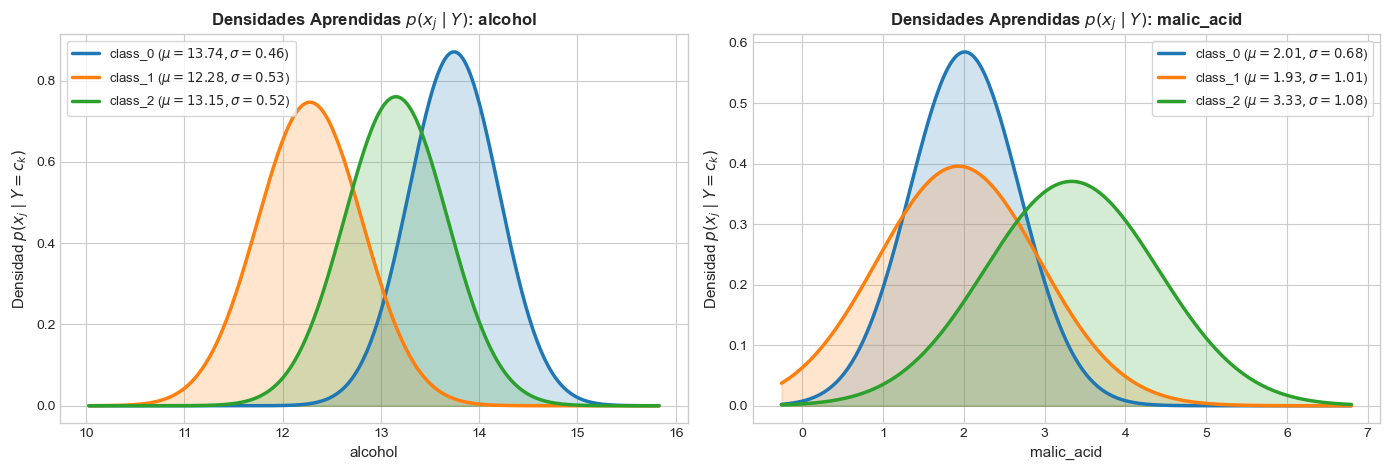

In [7]:
# 📊 Paso 4: Auditoría Empírica de los Estimadores MLE en Scikit-Learn y Visualización de Campanas Aprendidas
wine = load_wine()
X_wine, y_wine = wine.data, wine.target
feature_names = wine.feature_names

# Entrenamos con var_smoothing=0 para verificar la identidad exacta con la fórmula MLE
gnb_exact = GaussianNB(var_smoothing=0.0).fit(X_wine, y_wine)

# Cálculo manual en NumPy para la Clase 0
X_c0 = X_wine[y_wine == 0]
mu_c0_manual = np.mean(X_c0, axis=0)
var_c0_manual = np.var(X_c0, axis=0, ddof=0) # MLE usa ddof=0 (divide entre N_k)

print("=== AUDITORÍA DE ATRIBUTOS INTERNOS DE GAUSSIANNB ===")
print(f"Clases detectadas (classes_):       {gnb_exact.classes_}")
print(f"Conteo por clase (class_count_):    {gnb_exact.class_count_}")
print(f"Priors por clase (class_prior_):    {np.round(gnb_exact.class_prior_, 4)}")
print(f"Dimensiones de theta_ (Medias):     {gnb_exact.theta_.shape}")
print(f"Dimensiones de var_ (Varianzas):    {gnb_exact.var_.shape}\n")

diff_theta = np.max(np.abs(gnb_exact.theta_[0] - mu_c0_manual))
diff_var = np.max(np.abs(gnb_exact.var_[0] - var_c0_manual))

print(f"Diferencia máxima en Media (theta_[0] vs np.mean):        {diff_theta:.2e}")
print(f"Diferencia máxima en Varianza (var_[0] vs np.var ddof=0): {diff_var:.2e}")

# Visualización de las campanas Gaussianas aprendidas para las 2 primeras características
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colores = ['#1f77b4', '#ff7f0e', '#2ca02c']

for j, ax in enumerate(axes):
    x_min, x_max = X_wine[:, j].min() - 1.0, X_wine[:, j].max() + 1.0
    x_Axis = np.linspace(x_min, x_max, 300)
    
    for c_idx, c_name in enumerate(wine.target_names):
        mu = gnb_exact.theta_[c_idx, j]
        sigma = np.sqrt(gnb_exact.var_[c_idx, j])
        pdf = stats.norm.pdf(x_Axis, loc=mu, scale=sigma)
        
        ax.plot(x_Axis, pdf, color=colores[c_idx], lw=2.5, label=f"{c_name} ($\mu={mu:.2f}, \sigma={sigma:.2f}$)")
        ax.fill_between(x_Axis, pdf, color=colores[c_idx], alpha=0.2)
        
    ax.set_title(f"Densidades Aprendidas $p(x_j \mid Y)$: {feature_names[j]}", fontsize=12, fontweight='bold')
    ax.set_xlabel(feature_names[j], fontsize=11)
    ax.set_ylabel("Densidad $p(x_j \mid Y=c_k)$", fontsize=11)
    ax.legend(frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()

---

## 3. Geometría de las Fronteras de Decisión: Covarianza Diagonal vs. LDA y QDA

###  Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Un mito muy extendido en entrevistas técnicas es creer que Naive Bayes es siempre un clasificador lineal.  
Imagina que en un sistema de detección de intrusos la **Clase 0 (Tráfico Normal)** está muy concentrada alrededor del origen, mientras que la **Clase 1 (Ataques de Red)** está ampliamente dispersa alrededor de ella con una varianza mucho mayor. Un hiperplano recto (como Regresión Logística o LDA) es incapaz de encerrar una nube compacta rodeada por otra dispersa.  
**¿Qué forma geométrica tienen las curvas de nivel y la frontera de decisión de `GaussianNB`, y cómo se diferencian visualmente de LDA y QDA?**

---

###  Paso 2: Formalismo Matemático Riguroso

Analicemos matemáticamente el lugar geométrico de la frontera de decisión entre dos clases $c_1$ y $c_2$ en $\mathbb{R}^D$, el cual ocurre donde las funciones discriminantes logarítmicas se igualan: $\ell_1(\mathbf{x}) - \ell_2(\mathbf{x}) = 0$:

$$\ln \frac{P(Y=c_1)}{P(Y=c_2)} - \frac{1}{2}\sum_{j=1}^{D} \ln \frac{\sigma_{1j}^2}{\sigma_{2j}^2} - \frac{1}{2} \sum_{j=1}^{D} \left[ \frac{(x_j - \mu_{1j})^2}{\sigma_{1j}^2} - \frac{(x_j - \mu_{2j})^2}{\sigma_{2j}^2} \right] = 0$$

Al expandir los binomios al cuadrado $(x_j - \mu_{kj})^2 = x_j^2 - 2\mu_{kj}x_j + \mu_{kj}^2$, agrupamos la ecuación como una forma cuadrática en las coordenadas $x_j$:

$$\sum_{j=1}^{D} a_j x_j^2 + \sum_{j=1}^{D} b_j x_j + c = 0$$

donde los coeficientes vienen dados explícitamente por:

$$a_j = -\frac{1}{2}\left(\frac{1}{\sigma_{1j}^2} - \frac{1}{\sigma_{2j}^2}\right), \quad b_j = \frac{\mu_{1j}}{\sigma_{1j}^2} - \frac{\mu_{2j}}{\sigma_{2j}^2}, \quad c = \ln\frac{P(Y=c_1)}{P(Y=c_2)} - \frac{1}{2}\sum_{j=1}^{D}\left(\ln\frac{\sigma_{1j}^2}{\sigma_{2j}^2} + \frac{\mu_{1j}^2}{\sigma_{1j}^2} - \frac{\mu_{2j}^2}{\sigma_{2j}^2}\right)$$

Observa un hecho algebraico decisivo: **no existen términos bilineales cruzados $x_i x_j$ ($i \neq j$)** porque la matriz de covarianza $\boldsymbol{\Sigma}_k = \text{diag}(\sigma_{k1}^2, \dots, \sigma_{kD}^2)$ tiene ceros fuera de la diagonal.

---

### ] Paso 3: Traducción "En Palabras Claras" (Comparativa de la Familia Generativa Gaussiana)

| Modelo Generativo | Estructura de Covarianza $\boldsymbol{\Sigma}_k$ | Geometría de Curvas de Nivel (Isodensidad) | Geometría de la Frontera de Decisión | Parámetros de Covarianza a Estimar |
| :--- | :--- | :--- | :--- | :--- |
| **LDA** (*Linear Discriminant Analysis*) | Compartida entre todas las clases ($\boldsymbol{\Sigma}_k = \boldsymbol{\Sigma}$) y completa. | Elipses idénticas e inclinadas con el mismo ángulo para todas las clases. | **Hiperplano Lineal** (los términos cuadráticos se cancelan exactamente). | $\frac{D(D+1)}{2}$ |
| **GaussianNB** (*Naive Bayes*) | Propia por clase, pero **estrictamente diagonal**: $\boldsymbol{\Sigma}_k = \text{diag}(\sigma_{k1}^2, \dots, \sigma_{kD}^2)$. | **Elipses alineadas a los ejes coordenados** (prohibido rotar en diagonal). | **Cuadrática (Parábolas, Elipses o Hipérbolas)** si $\sigma_{1j}^2 \neq \sigma_{2j}^2$; colapsa a lineal si $\sigma_{1j}^2 = \sigma_{2j}^2$. | $C \cdot D$ (**Escala a alta dimensión**) |
| **QDA** (*Quadratic Discriminant Analysis*) | Propia por clase y **completa** (con covarianzas cruzadas $\sigma_{ij}$). | Elipses libres que pueden **rotar en cualquier ángulo** según la correlación intra-clase. | **Sección Cónica General Rotada** (incluye términos cruzados $x_i x_j$). | $C \cdot \frac{D(D+1)}{2}$ (Sobreajusta si $D$ es grande) |

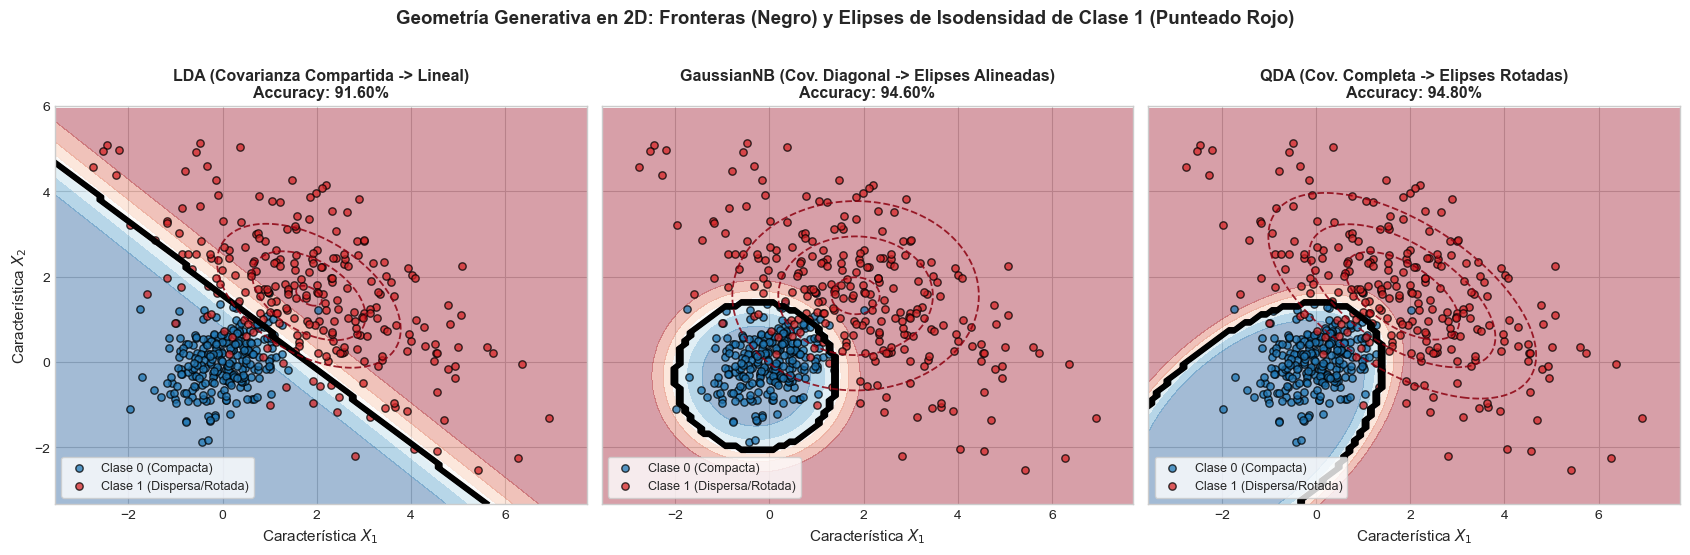

💡 Observación Geométrica Clave:
• Observa las elipses punteadas rojas en el panel central (GaussianNB): sus ejes están perfectamente horizontales y verticales porque su matriz de covarianza es diagonal.
• En el panel derecho (QDA), las elipses punteadas rotan en diagonal siguiendo la inclinación real de los puntos rojos.


In [8]:
# 📊 Paso 4: Comparación Visual de Contornos de Isodensidad (Elipses Alineadas vs Rotadas) y Fronteras 2D
np.random.seed(42)

# Generamos un dataset 2D donde la Clase 0 es compacta y la Clase 1 es dispersa y rotada (con correlación negativa)
N_pts = 250
X_class0 = np.random.multivariate_normal(mean=[0.0, 0.0], cov=[[0.4, 0.1], [0.1, 0.4]], size=N_pts)
X_class1 = np.random.multivariate_normal(mean=[1.8, 1.5], cov=[[3.2, -1.8], [-1.8, 2.5]], size=N_pts)

X_2d = np.vstack([X_class0, X_class1])
y_2d = np.array([0]*N_pts + [1]*N_pts)

modelos_2d = [
    ("LDA (Covarianza Compartida -> Lineal)", LinearDiscriminantAnalysis(store_covariance=True)),
    ("GaussianNB (Cov. Diagonal -> Elipses Alineadas)", GaussianNB()),
    ("QDA (Cov. Completa -> Elipses Rotadas)", QuadraticDiscriminantAnalysis(store_covariance=True))
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), sharex=True, sharey=True)

# Malla para dibujar las elipses de isodensidad (1 y 2 desviaciones estándar) de la Clase 1
xg, yg = np.meshgrid(np.linspace(-2.5, 6.5, 150), np.linspace(-3.0, 6.0, 150))
pos_grid = np.dstack((xg, yg))

for ax, (titulo, clf) in zip(axes, modelos_2d):
    clf.fit(X_2d, y_2d)
    acc = clf.score(X_2d, y_2d)
    
    # Superficie de probabilidad y frontera con DecisionBoundaryDisplay
    DecisionBoundaryDisplay.from_estimator(
        clf, X_2d, response_method="predict_proba", cmap="RdBu_r", alpha=0.40, ax=ax, eps=0.8
    )
    DecisionBoundaryDisplay.from_estimator(
        clf, X_2d, response_method="predict", plot_method="contour", colors="black", linewidths=2.2, ax=ax, eps=0.8
    )
    
    # Extraemos la matriz de covarianza que cada modelo asume para la Clase 1 y trazamos sus elipses
    if isinstance(clf, GaussianNB):
        mu_c1 = clf.theta_[1]
        cov_c1 = np.diag(clf.var_[1]) # Estrictamente diagonal (Ejes paralelos a X1 y X2)
    elif isinstance(clf, LinearDiscriminantAnalysis):
        mu_c1 = clf.means_[1]
        cov_c1 = clf.covariance_
    else:
        mu_c1 = clf.means_[1]
        cov_c1 = clf.covariance_[1]
        
    rv_c1 = stats.multivariate_normal(mu_c1, cov_c1)
    ax.contour(xg, yg, rv_c1.pdf(pos_grid), levels=3, colors='#8c000f', linestyles='dashed', linewidths=1.3, alpha=0.85)
    
    ax.scatter(X_class0[:, 0], X_class0[:, 1], c='#1f77b4', edgecolors='k', s=28, alpha=0.75, label='Clase 0 (Compacta)')
    ax.scatter(X_class1[:, 0], X_class1[:, 1], c='#d62728', edgecolors='k', s=28, alpha=0.75, label='Clase 1 (Dispersa/Rotada)')
    ax.set_title(f"{titulo}\nAccuracy: {acc:.2%}", fontsize=11.5, fontweight='bold')
    ax.set_xlabel("Característica $X_1$", fontsize=11)
    if ax == axes[0]:
        ax.set_ylabel("Característica $X_2$", fontsize=11)
    ax.legend(loc='lower left', frameon=True, facecolor='white', fontsize=9)

plt.suptitle("Geometría Generativa en 2D: Fronteras (Negro) y Elipses de Isodensidad de Clase 1 (Punteado Rojo)", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("💡 Observación Geométrica Clave:")
print("• Observa las elipses punteadas rojas en el panel central (GaussianNB): sus ejes están perfectamente horizontales y verticales porque su matriz de covarianza es diagonal.")
print("• En el panel derecho (QDA), las elipses punteadas rotan en diagonal siguiendo la inclinación real de los puntos rojos.")

---

## 4. El Hiperparámetro `var_smoothing` Desmitificado: De Salvavidas Numérico a Regularización

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Imagina que entrenas un clasificador de fraude con 50 columnas continuas. Una de esas columnas es `Monto_Retiro_Cajero_Internacional`. En los datos de entrenamiento de la **Clase Minoritaria**, todos los clientes tienen `0.00` en esa columna.  
Por lo tanto, para esa clase, la media es $\hat{\mu} = 0.0$ y **la varianza es exactamente $\hat{\sigma}^2 = 0.0$**.  
Al día siguiente, en producción, llega una transacción donde esa columna vale `$10.0`. Cuando `GaussianNB` intenta evaluar la fórmula de la campana Gaussiana:
1. El factor de escala $\frac{1}{\sqrt{2\pi\sigma^2}} = \frac{1}{0}$ **explota hacia $+\infty$**.
2. El exponente $-\frac{(10 - 0)^2}{2 \times 0} = -\frac{100}{0}$ **explota hacia $-\infty$**.
3. La resta $\infty - \infty$ produce una **indeterminación numérica (`NaN`)** que derriba el servicio en producción.

**¿Cómo evita Scikit-Learn esta catástrofe matemática y cómo podemos usar ese mismo mecanismo para regularizar fronteras sobreajustadas?**

---

### 📐 Paso 2: Formalismo Matemático Riguroso

Scikit-Learn garantiza que ninguna varianza sea cero sumando un término de estabilización isotrópico $\epsilon_{\text{abs}}$ (`epsilon_`) a todas las varianzas MLE estimadas:

$$\sigma_{\text{smoothed}, kj}^2 = \hat{\sigma}_{kj}^2 + \varepsilon \cdot \max_{m \in \{1,\dots,D\}} \text{Var}(X_m)$$

donde:
* $\varepsilon = \text{var\_smoothing}$ es el hiperparámetro configurable por el usuario (por defecto $\varepsilon = 10^{-9}$).
* $\max_{m} \text{Var}(X_m)$ es la varianza global máxima entre todas las características del dataset de entrenamiento sin distinguir clases: `np.var(X, axis=0).max()`.

#### Efecto Asintótico sobre la Frontera de Decisión (Regularización / *Shrinkage*)
Recordemos que el coeficiente cuadrático que curva la frontera de decisión entre las clases $c_1$ y $c_2$ es:

$$a_j(\varepsilon) = -\frac{1}{2}\left( \frac{1}{\hat{\sigma}_{1j}^2 + \varepsilon \sigma_{\max}^2} - \frac{1}{\hat{\sigma}_{2j}^2 + \varepsilon \sigma_{\max}^2} \right)$$

Cuando incrementamos $\varepsilon$ hacia valores grandes ($\varepsilon \in [10^{-2}, 1.0]$):
1. Las diferencias relativas entre $\sigma_{\text{smoothed}, 1j}^2$ y $\sigma_{\text{smoothed}, 2j}^2$ disminuyen, haciendo que $a_j(\varepsilon) \to 0$ (**la frontera cuadrática se aplana gradualmente hacia una frontera lineal**).
2. Si $\varepsilon$ es excesivamente grande ($\varepsilon \gg 1$), todas las campanas se vuelven tan planas que las características pierden poder discriminativo y el modelo cae en **subajuste (*underfitting*)**, clasificando casi exclusivamente por el *Prior*.

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Régimen de `var_smoothing` ($\varepsilon$) | Rol Técnico | Efecto Geométrico y en el Compromiso Sesgo-Varianza |
| :--- | :--- | :--- |
| **$\varepsilon = 0.0$** | Desactivado (Peligroso) | Si existe una sola columna constante en una clase ($\hat{\sigma}_{kj}^2 = 0$), el modelo lanza `RuntimeWarning: divide by zero` y devuelve `NaN`. |
| **$\varepsilon = 10^{-9}$ (Default)** | Salvavidas Numérico Puro | Evita divisiones por cero sin alterar en absoluto la curvatura natural de las fronteras cuadráticas. |
| **$\varepsilon \in [10^{-3}, 10^{-1}]$** | Regularizador Geométrico (*Shrinkage*) | Ensancha las campanas más estrechas, reduciendo la varianza del estimador y suavizando fronteras cuadráticas ruidosas. |
| **$\varepsilon \ge 1.0$** | Subajuste (*Underfitting*) | Homogeneiza excesivamente las varianzas entre clases; aplana las campanas y degrada la capacidad de separación. |

=== 1. SIMULACIÓN DE COLUMNA CON VARIANZA CERO EN ENTRENAMIENTO ===
Varianza aprendida en Clase 0 sin suavizado: [0.02666667 0.        ]
predict_proba con var_smoothing=0.0  -> [[nan nan]] (¡Colapso numérico!)
predict_proba con var_smoothing=1e-9 -> [[0. 1.]] (Estable)



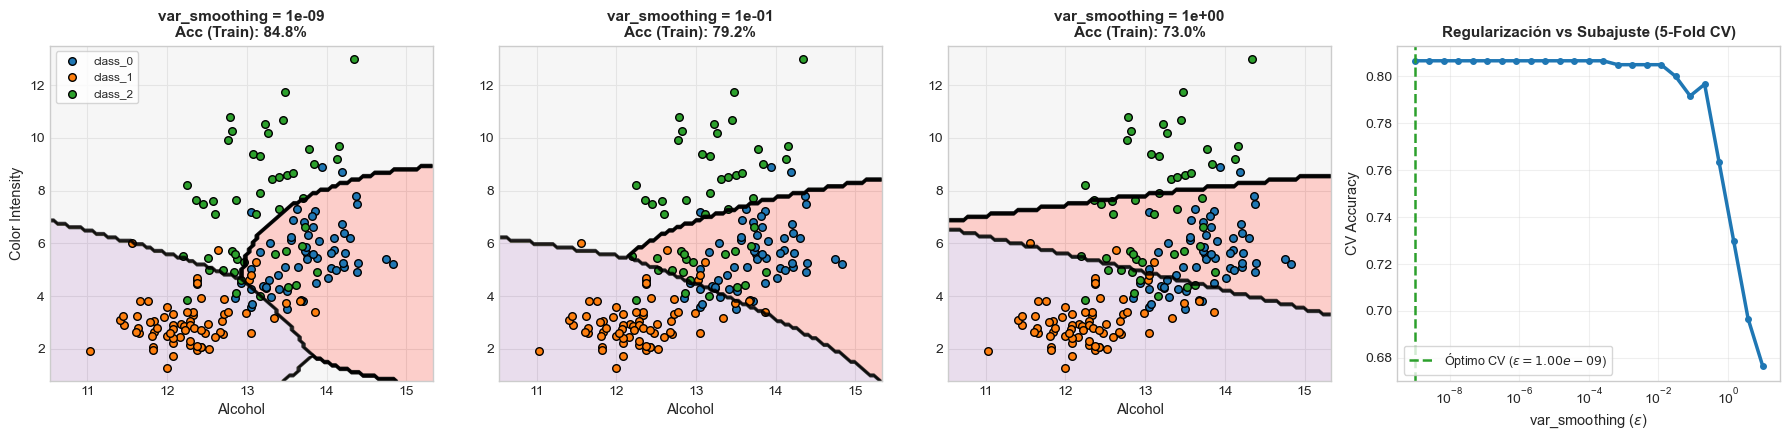

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine, make_classification
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import DecisionBoundaryDisplay

# 📊 Paso 4: Prueba Experimental de Catástrofe por Varianza Cero y Curva de Regularización con var_smoothing
np.random.seed(42)

# Cargar dataset Wine
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

# 1. Demostración de la Catástrofe de Varianza Cero (var_smoothing=0 vs 1e-9)
# Clase 0: Columna 1 es constante (0.0 -> varianza = 0)
# Clase 1: Columna 1 varía normalmente
X_deg = np.array([
    [1.0, 0.0], [1.2, 0.0], [0.8, 0.0],
    [3.0, 1.0], [3.5, 2.0], [2.8, 1.5]
])
y_deg = np.array([0, 0, 0, 1, 1, 1])

with np.errstate(divide='ignore', invalid='ignore'):
    gnb_zero = GaussianNB(var_smoothing=0.0).fit(X_deg, y_deg)
    pred_proba_zero = gnb_zero.predict_proba([[1.1, 0.5]])

gnb_safe = GaussianNB(var_smoothing=1e-9).fit(X_deg, y_deg)
pred_proba_safe = gnb_safe.predict_proba([[1.1, 0.5]])

print("=== 1. SIMULACIÓN DE COLUMNA CON VARIANZA CERO EN ENTRENAMIENTO ===")
print(f"Varianza aprendida en Clase 0 sin suavizado: {gnb_zero.var_[0]}")
print(f"predict_proba con var_smoothing=0.0  -> {pred_proba_zero} (¡Colapso numérico!)")
print(f"predict_proba con var_smoothing=1e-9 -> {np.round(pred_proba_safe, 4)} (Estable)\n")

# 2. Experimento en Dataset Sintético Ruidoso: Evolución de var_smoothing desde 1e-9 hasta 10.0
X_syn, y_syn = make_classification(
    n_samples=600, n_features=15, n_informative=5, n_redundant=5,
    flip_y=0.08, class_sep=0.9, random_state=42
)

grid_eps = np.logspace(-9, 1, 25)
cv_smooth = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mean_acc_syn = [cross_val_score(GaussianNB(var_smoothing=e), X_syn, y_syn, cv=cv_smooth).mean() for e in grid_eps]

# Visualización combinada: Fronteras en Wine (3 niveles) + Curva de Regularización
X_wine_2d = X_wine[:, [0, 9]]  # Alcohol vs Color Intensity
smoothing_values = [1e-9, 1e-1, 1.0]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
palette_wine = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, eps_val in zip(axes[:3], smoothing_values):
    clf_smooth = GaussianNB(var_smoothing=eps_val).fit(X_wine_2d, y_wine)
    acc_val = clf_smooth.score(X_wine_2d, y_wine)
    
    DecisionBoundaryDisplay.from_estimator(
        clf_smooth, X_wine_2d, response_method="predict", cmap="Pastel1", alpha=0.65, ax=ax, eps=0.5
    )
    DecisionBoundaryDisplay.from_estimator(
        clf_smooth, X_wine_2d, response_method="predict", plot_method="contour", colors="k", linewidths=1.2, alpha=0.7, ax=ax, eps=0.5
    )
    for c_idx, c_name in enumerate(wine.target_names):
        mask = (y_wine == c_idx)
        ax.scatter(X_wine_2d[mask, 0], X_wine_2d[mask, 1], c=palette_wine[c_idx], edgecolors='k', s=30, label=c_name)
    ax.set_title(f"var_smoothing = {eps_val:.0e}\nAcc (Train): {acc_val:.1%}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Alcohol", fontsize=10.5)
    if ax == axes[0]:
        ax.set_ylabel("Color Intensity", fontsize=10.5)
        ax.legend(loc='upper left', fontsize=8.5, frameon=True, facecolor='white')

# Panel 4: Curva de Validación Cruzada (Regularización vs Subajuste)
best_idx = int(np.argmax(mean_acc_syn))
axes[3].plot(grid_eps, mean_acc_syn, color='#1f77b4', lw=2.5, marker='o', markersize=4)
axes[3].axvline(grid_eps[best_idx], color='#2ca02c', linestyle='--', lw=1.8,
                label=fr'Óptimo CV ($\varepsilon={grid_eps[best_idx]:.2e}$)')
axes[3].set_xscale('log')
axes[3].set_title('Regularización vs Subajuste (5-Fold CV)', fontsize=11, fontweight='bold')
axes[3].set_xlabel(r'var_smoothing ($\varepsilon$)', fontsize=10.5)
axes[3].set_ylabel('CV Accuracy', fontsize=10.5)
axes[3].legend(loc='lower left', frameon=True, facecolor='white', fontsize=9)
axes[3].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()


---

#### 1. El Colapso Numérico: ¿Por qué ocurre `nan nan` en la consola?

La función de densidad de probabilidad gaussiana que calcula GaussianNB para cada característica es:

$$P(X_j = x \mid Y = c) = \frac{1}{\sqrt{2\pi \sigma_{jc}^2}} \exp\left( -\frac{(x - \mu_{jc})^2}{2\sigma_{jc}^2} \right)$$

* **El problema de la varianza cero:**  
  Si dentro de una clase una columna es constante (ej. un sensor congelado en `0.0` o una característica booleana invariable), la varianza empírica es exactamente cero: $\sigma_{jc}^2 = 0$.
* **La catástrofe algebraica:**  
  * En el factor de normalización: $\frac{1}{\sqrt{2\pi \cdot 0}} = \frac{1}{0} \to \infty$.
  * En el exponente: $-\frac{(x - \mu)^2}{2 \cdot 0} = -\infty$, lo que da $e^{-\infty} = 0$.
  * Al multiplicar $\infty \times 0$ en el espacio flotante de la CPU, el procesador produce una indeterminación matemática inmediata: **`NaN` (Not a Number)**.
* **La solución de Scikit-Learn (`var_smoothing`):**  
  Suma una pequeña fracción $\varepsilon$ a la varianza calculada de cada característica:
  $$\sigma_{\text{efectiva}}^2 = \sigma_{jc}^2 + \varepsilon \cdot \max(\sigma_{\text{global}}^2)$$
  * Con $\varepsilon = 0.0$: la consola arroja `[[nan nan]]` y el clasificador colapsa por completo.
  * Con $\varepsilon = 10^{-9}$ (valor por defecto de `GaussianNB`): la varianza mínima queda acotada numéricamente y la predicción se estabiliza de forma determinista (`[[0., 1.]]`).

---

#### 2. Efecto Geométrico en las Fronteras de Decisión (Paneles 1, 2 y 3: Dataset Wine)

| Nivel de Suavizado | Parámetro | Accuracy (Train) | Comportamiento Geométrico de la Frontera | Diagnóstico |
| :--- | :--- | :---: | :--- | :--- |
| **Bajo (Default)** | `var_smoothing = 1e-9` | **84.8%** | **Curvada / Cuadrática:** Modela fielmente las varianzas reales e independientes de cada clase de vino. | **Ajuste Óptimo** |
| **Intermedio** | `var_smoothing = 1e-1` | **79.2%** | **Pérdida de Curvatura:** El término $\varepsilon$ empieza a competir con la varianza real; las fronteras se enderezan. | **Pérdida de Flexibilidad** |
| **Excesivo** | `var_smoothing = 1e+0` | **73.0%** | **Casi Lineal / Bandas Paralelas:** $\varepsilon$ domina completamente y borra las diferencias de dispersión entre clases. | **Subajuste (Underfitting)** |

##### ¿Por qué las fronteras se aplanan al subir `var_smoothing`?
En Naive Bayes Gaussiano, la frontera entre dos clases es una función cuadrática porque cada clase $c$ tiene su propia varianza $\sigma_c^2$. 

Cuando hacemos $\varepsilon$ muy grande ($\varepsilon = 1.0$), la varianza efectiva de todas las clases converge al mismo valor artificial: $\sigma_0^2 + \varepsilon \approx \sigma_1^2 + \varepsilon \approx \varepsilon$. Al tener todas las clases la misma varianza, los términos cuadráticos $x^2$ se cancelan en el logaritmo de verosimilitudes y la frontera **se degrada forzosamente a una recta o hiperplano lineal** (equivalente a un Análisis Discriminante Lineal - LDA), incapaz de separar la curvatura real de los datos.

---

#### 3. Curva de Validación Cruzada: Regularización vs. Subajuste (Panel 4)

El panel derecho evalúa el impacto de $\varepsilon$ sobre datos sintéticos con 5-Fold Cross Validation:

* **Zona Estable ($\varepsilon \in [10^{-9}, 10^{-2}]$):**  
  El Accuracy se mantiene constante y óptimo en torno al **$81\%$**. En este rango, el parámetro cumple su función de protección numérica sin distorsionar la señal de las características.
* **Zona de Colapso por Subajuste ($\varepsilon > 10^{-2}$ hacia $10^1$):**  
  El rendimiento cae drásticamente del **$81\%$ hasta menos del $68\%$**.  
  * Al inflar artificialmente la varianza de todas las columnas, las campanas de Gauss se vuelven extremadamente anchas y planas.
  * Para el modelo, cualquier punto parece igualmente probable bajo cualquier clase, destruyendo su capacidad de discriminación.

---

#### 4. Resumen para Producción e Ingeniería de Machine Learning

1. **`var_smoothing` NO es un hiperparámetro para ganar accuracy masivo:** Su función primordial es la **estabilidad numérica** frente a divisiones por cero.
2. **El valor por defecto (`1e-9`) es el estándar recomendado:** Solo conviene aumentarlo ligeramente si se detecta sobreajuste severo en datasets pequeños con pocas muestras por clase.
3. **Peligro de modificarlo sin validación:** Fijar un `var_smoothing` arbitrariamente alto ($> 0.1$) induce un sesgo masivo que convierte el clasificador probabilístico en un modelo rígido y subajustado.

---

## 5. Cuando la Gaussiana Falla en la Vida Real: Asimetría (*Skewness*), Multimodalidad y `PowerTransformer`

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
`GaussianNB` asume que cada característica dentro de cada clase tiene forma de campana simétrica unimodal. Pero en la ingeniería de datos del mundo real, esta suposición se rompe en dos escenarios clásicos:
1. **Variables con Asimetría Severa (*Right-Skewed / Heavy-Tailed*):** Ingresos salariales, montos de crédito, tiempos de latencia en servidores o conteos de actividad siguen distribuciones Log-Normal o Pareto (muchos valores pequeños y unos pocos valores gigantescos en la cola derecha). Al ajustar una Gaussiana simétrica, los *outliers* de la derecha arrastran la media $\hat{\mu}$ y disparan la varianza $\hat{\sigma}^2$, asignando probabilidad alta a valores negativos imposibles.
2. **Variables Multimodales (Doble Pico):** Imagina que la Clase 0 (Clientes Normales) realiza compras o bien muy pequeñas ($\$10$) o bien muy grandes ($\$1,000$), pero casi nunca intermedias ($\$500$), mientras que la Clase 1 (Fraude) opera justo en el medio ($\$500$). Cuando `GaussianNB` calcula la media de la Clase 0, ¡coloca el pico de su campana Gaussiana exactamente en $\$500$ (en el valle vacío entre los dos picos reales)!, saboteando la clasificación.

**¿Cómo diagnosticamos estas patologías y cómo reparamos la asimetría automáticamente dentro de un `Pipeline` de producción?**

---

### 📐 Paso 2: Formalismo Matemático Riguroso (Transformación de Potencia de Yeo-Johnson)

Para corregir la asimetría y acercar cualquier distribución continua unimodal sesgada hacia una Gaussiana estándar $\mathcal{N}(0, 1)$, aplicamos la familia de transformaciones paramétricas monótonas de **Yeo-Johnson (2000)** (que generaliza a Box-Cox admitiendo valores $x \in \mathbb{R}$, incluyendo ceros y negativos):

$$\psi(\lambda_j, x_j) = \begin{cases} \dfrac{(x_j + 1)^{\lambda_j} - 1}{\lambda_j} & \text{si } \lambda_j \neq 0, \; x_j \geq 0 \\[8pt] \ln(x_j + 1) & \text{si } \lambda_j = 0, \; x_j \geq 0 \\[8pt] -\dfrac{(-x_j + 1)^{2 - \lambda_j} - 1}{2 - \lambda_j} & \text{si } \lambda_j \neq 2, \; x_j < 0 \\[8pt] -\ln(-x_j + 1) & \text{si } \lambda_j = 2, \; x_j < 0 \end{cases}$$

Durante `PowerTransformer(method='yeo-johnson').fit(X_train)`, Scikit-Learn estima para cada columna $j$ el parámetro óptimo $\hat{\lambda}_j$ que maximiza la log-verosimilitud de normalidad (minimizando la asimetría de Fisher-Pearson $\gamma_1 = \mathbb{E}\left[\left(\frac{X - \mu}{\sigma}\right)^3\right] \to 0$).

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (Guía de Ingeniería ante Violaciones de Normalidad)

| Patología en los Datos Reales | Síntoma Matemático en `GaussianNB` | Solución de Ingeniería Recomendada |
| :--- | :--- | :--- |
| **Asimetría Positiva/Negativa ($|\text{skew}| > 1.0$)** | La cola larga infla $\hat{\sigma}_{kj}^2$; la campana se desborda hacia zonas sin datos y pierde precisión en la región densa. | Encapsular en un `Pipeline` con **`PowerTransformer(method='yeo-johnson')`** (o `QuantileTransformer(output_distribution='normal')`). |
| **Distribución Multimodal Intra-Clase (2 o más picos por clase)** | La media $\hat{\mu}_{kj}$ cae en el "valle fantasma" entre los picos. `PowerTransformer` (al ser monótono) **no puede fusionar dos picos en uno**. | Sustituir la densidad univariada por un **Modelo de Mezclas Gaussianas (`GaussianMixture` / GMM)** por clase, usar *Kernel Density Estimation* (KDE), o cambiar a Árboles/ Bosques. |

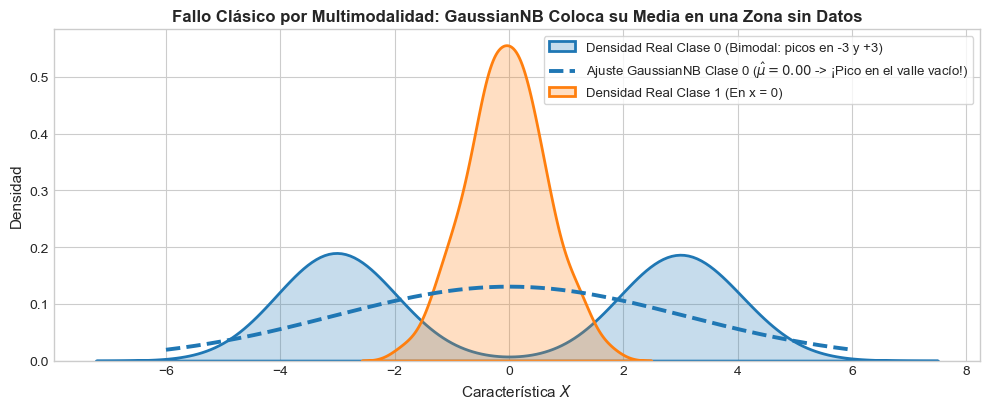

In [11]:
# 📊 Paso 4 (Parte A): Visualización de la Patología Multimodal (El "Valle Fantasma" de la Gaussiana Única)
np.random.seed(42)

# Clase 0 es bimodal: picos en -3.0 y +3.0 (valle vacío en 0.0)
x_bimodal_c0 = np.concatenate([np.random.normal(-3.0, 0.6, 250), np.random.normal(3.0, 0.6, 250)])
# Clase 1 es unimodal: concentrada justo en el valle (0.0)
x_unimodal_c1 = np.random.normal(0.0, 0.7, 250)

X_mm = np.concatenate([x_bimodal_c0, x_unimodal_c1]).reshape(-1, 1)
y_mm = np.array([0]*500 + [1]*250)

gnb_mm = GaussianNB().fit(X_mm, y_mm)
x_axis_mm = np.linspace(-6, 6, 400)
pdf_mm_c0 = stats.norm.pdf(x_axis_mm, loc=gnb_mm.theta_[0, 0], scale=np.sqrt(gnb_mm.var_[0, 0]))

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.kdeplot(x_bimodal_c0, ax=ax, color='#1f77b4', fill=True, alpha=0.25, lw=2, label='Densidad Real Clase 0 (Bimodal: picos en -3 y +3)')
ax.plot(x_axis_mm, pdf_mm_c0, color='#1f77b4', linestyle='--', lw=2.8, label=f'Ajuste GaussianNB Clase 0 ($\hat{{\mu}}={gnb_mm.theta_[0,0]:.2f}$ -> ¡Pico en el valle vacío!)')
sns.kdeplot(x_unimodal_c1, ax=ax, color='#ff7f0e', fill=True, alpha=0.25, lw=2, label='Densidad Real Clase 1 (En x = 0)')
ax.set_title('Fallo Clásico por Multimodalidad: GaussianNB Coloca su Media en una Zona sin Datos', fontsize=12, fontweight='bold')
ax.set_xlabel('Característica $X$', fontsize=11)
ax.set_ylabel('Densidad', fontsize=11)
ax.legend(frameon=True, facecolor='white', fontsize=9.5)
plt.tight_layout()
plt.show()

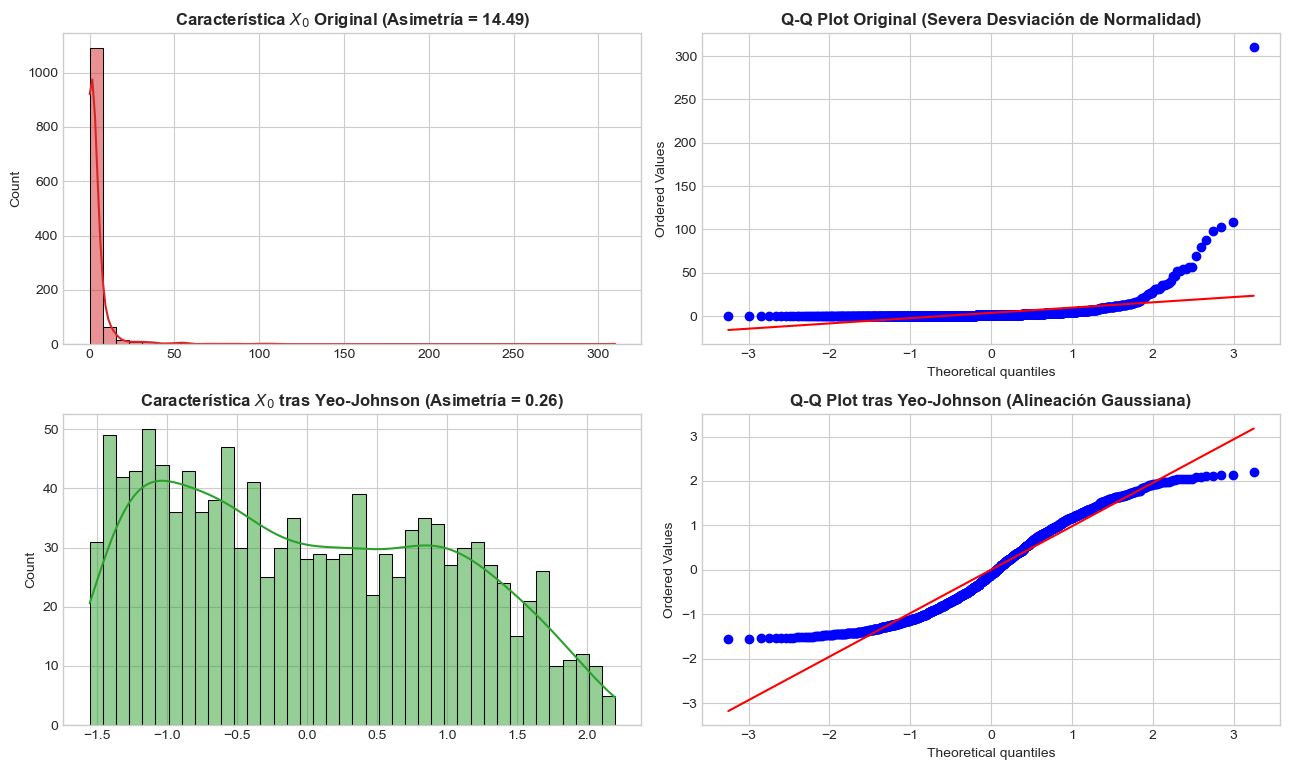

=== IMPACTO DE POWERTRANSFORMER EN EL RENDIMIENTO DE GAUSSIANNB (10-Fold CV) ===
Accuracy sin transformar (Datos Asimétricos): 55.92% ± 3.52% | F1-Macro: 0.5171
Accuracy con Pipeline PowerTransformer:       73.92% ± 3.33% | F1-Macro: 0.7387
Ganancia neta en Accuracy:                    +18.00 puntos porcentuales


In [14]:
# 📊 Paso 4 (Parte B): Corrección de Asimetría Severa (Skewness) con PowerTransformer(method='yeo-johnson')
np.random.seed(42)

# Generamos un dataset multiclase realista y aplicamos una transformación exponencial
# para simular características financieras/químicas con fuerte sesgo positivo (Log-Normal)
X_base, y_skew = make_classification(
    n_samples=1200, n_features=10, n_informative=8, n_redundant=2,
    n_classes=3, class_sep=1.1, random_state=42
)
X_skewed = X_base.copy()
for j in range(6):
    X_skewed[:, j] = np.exp(0.85 * X_base[:, j])

# Calculamos el coeficiente de asimetría de Fisher-Pearson con SciPy
skew_antes = stats.skew(X_skewed[:, 0])
pt = PowerTransformer(method='yeo-johnson', standardize=True)
X_transformed_sample = pt.fit_transform(X_skewed)
skew_despues = stats.skew(X_transformed_sample[:, 0])

# Visualización del efecto de PowerTransformer (Histograma + Q-Q Plot)
fig, axes = plt.subplots(2, 2, figsize=(13, 7.8))

sns.histplot(X_skewed[:, 0], kde=True, ax=axes[0, 0], color='#d62728', bins=40)
axes[0, 0].set_title(f"Característica $X_0$ Original (Asimetría = {skew_antes:.2f})", fontweight='bold')

stats.probplot(X_skewed[:, 0], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot Original (Severa Desviación de Normalidad)", fontweight='bold')

sns.histplot(X_transformed_sample[:, 0], kde=True, ax=axes[1, 0], color='#2ca02c', bins=40)
axes[1, 0].set_title(f"Característica $X_0$ tras Yeo-Johnson (Asimetría = {skew_despues:.2f})", fontweight='bold')

stats.probplot(X_transformed_sample[:, 0], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot tras Yeo-Johnson (Alineación Gaussiana)", fontweight='bold')

plt.tight_layout()
plt.show()

# Evaluación rigurosa con Validación Cruzada Estratificada (10-Fold): Accuracy y F1-Macro
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

pipe_crudo = Pipeline([('gnb', GaussianNB())])
pipe_yeo_johnson = Pipeline([
    ('power', PowerTransformer(method='yeo-johnson', standardize=True)),
    ('gnb', GaussianNB())
])

acc_crudo = cross_val_score(pipe_crudo, X_skewed, y_skew, cv=cv, scoring='accuracy')
acc_pt = cross_val_score(pipe_yeo_johnson, X_skewed, y_skew, cv=cv, scoring='accuracy')
f1_crudo = cross_val_score(pipe_crudo, X_skewed, y_skew, cv=cv, scoring='f1_macro')
f1_pt = cross_val_score(pipe_yeo_johnson, X_skewed, y_skew, cv=cv, scoring='f1_macro')

print("=== IMPACTO DE POWERTRANSFORMER EN EL RENDIMIENTO DE GAUSSIANNB (10-Fold CV) ===")
print(f"Accuracy sin transformar (Datos Asimétricos): {acc_crudo.mean():.2%} ± {acc_crudo.std():.2%} | F1-Macro: {f1_crudo.mean():.4f}")
print(f"Accuracy con Pipeline PowerTransformer:       {acc_pt.mean():.2%} ± {acc_pt.std():.2%} | F1-Macro: {f1_pt.mean():.4f}")
print(f"Ganancia neta en Accuracy:                    +{(acc_pt.mean() - acc_crudo.mean())*100:.2f} puntos porcentuales")

---

## 6. Invarianza de GaussianNB a la Escala Lineal de las Características

### 💡 Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En algoritmos basados en distancias euclidianas (como KNN o SVM) o con penalización L1/L2 (como Regresión Logística), si una columna está expresada en **pesos ($\$50,000$)** y otra en **años ($2.5$)**, la columna en miles domina por completo el modelo a menos que apliquemos `StandardScaler`.  
**¿Es necesario aplicar `StandardScaler` o `MinMaxScaler` antes de entrenar un `GaussianNB`?**  
Analíticamente, `GaussianNB` ya divide cada característica por su propia desviación estándar $\sigma_{kj}$ dentro del exponente Gaussiano (calcula un *Z-score* interno automático por clase). Sin embargo, existe un **sutil matiz de ingeniería en Scikit-Learn** relacionado con `var_smoothing` que todo *Senior ML Engineer* debe conocer.

---

### 📐 Paso 2: Formalismo Matemático Riguroso (Demostración de Invarianza Afín)

Supongamos que aplicamos una transformación lineal afín a cada característica $X_j$: sea $Z_j = a_j X_j + b_j$ con $a_j > 0$.
1. Por linealidad de la esperanza y propiedades de la varianza:
   $$\mu_{Z, kj} = a_j \mu_{X, kj} + b_j \quad \text{y} \quad \sigma_{Z, kj}^2 = a_j^2 \sigma_{X, kj}^2$$
2. El término cuadrático estandarizado (distancia de Mahalanobis univariada) permanece **exactamente invariante** porque los factores de escala $a_j$ y traslación $b_j$ se cancelan algebraicamente:
   $$\frac{(z_j - \mu_{Z, kj})^2}{\sigma_{Z, kj}^2} = \frac{(a_j x_j + b_j - (a_j \mu_{X, kj} + b_j))^2}{a_j^2 \sigma_{X, kj}^2} = \frac{a_j^2 (x_j - \mu_{X, kj})^2}{a_j^2 \sigma_{X, kj}^2} = \frac{(x_j - \mu_{X, kj})^2}{\sigma_{X, kj}^2}$$
3. En cuanto al término logarítmico de normalización:
   $$-\frac{1}{2}\sum_{j=1}^{D} \ln\left(2\pi a_j^2 \sigma_{X, kj}^2\right) = -\frac{1}{2}\sum_{j=1}^{D} \ln\left(2\pi \sigma_{X, kj}^2\right) - \underbrace{\sum_{j=1}^{D} \ln(a_j)}_{\text{Constante } \forall c_k}$$
   Dado que la suma $-\sum_{j=1}^D \ln(a_j)$ **no depende de la clase $c_k$**, suma la misma constante al puntaje logarítmico de todas las clases y se cancela exactamente al aplicar la normalización *Log-Sum-Exp*.

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (Teoría Pura vs. Implementación en Scikit-Learn)

* **En la teoría exacta (`var_smoothing = 0`):** Escalar o no escalar las variables produce exactamente las mismas probabilidades hasta el último bit de precisión ($10^{-16}$).
* **En la práctica con Scikit-Learn (`var_smoothing > 0`):** Recuerda que Scikit-Learn suma $\varepsilon \cdot \max_m \text{Var}(X_m)$ a **todas** las columnas. Si la columna $X_1$ está en millones ($\text{Var}(X_1) = 10^{12}$) y la columna $X_2$ está en milésimas ($\text{Var}(X_2) = 10^{-6}$), incluso con $\varepsilon = 10^{-9}$, el término suavizador será $10^{-9} \times 10^{12} = 1,000$, ¡aplastando por completo la varianza de $X_2$! Por ello, **incluir `StandardScaler` en el Pipeline garantiza que `var_smoothing` actúe de forma equitativa sobre todas las variables**.

In [13]:
# 📊 Paso 4: Verificación Empírica de la Invarianza al Escalamiento Lineal (StandardScaler)
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=42
)

# Caso 1: Sin var_smoothing (Teoría Gaussiana Pura)
gnb_raw_pure = GaussianNB(var_smoothing=0.0).fit(X_train_w, y_train_w)
pipe_scaled_pure = Pipeline([
    ('scaler', StandardScaler()),
    ('gnb', GaussianNB(var_smoothing=0.0))
]).fit(X_train_w, y_train_w)

prob_raw_pure = gnb_raw_pure.predict_proba(X_test_w)
prob_scaled_pure = pipe_scaled_pure.predict_proba(X_test_w)

diff_pure = np.max(np.abs(prob_raw_pure - prob_scaled_pure))
print(f"1. Diferencia máxima de probabilidades (Sin vs Con StandardScaler, var_smoothing=0):    {diff_pure:.2e}")

# Caso 2: Con var_smoothing moderado (1e-2) en Wine (donde 'Proline' tiene varianza ~99,000 y 'Nonflavanoid' ~0.015)
gnb_raw_smooth = GaussianNB(var_smoothing=1e-2).fit(X_train_w, y_train_w)
pipe_scaled_smooth = Pipeline([
    ('scaler', StandardScaler()),
    ('gnb', GaussianNB(var_smoothing=1e-2))
]).fit(X_train_w, y_train_w)

acc_raw_s = gnb_raw_smooth.score(X_test_w, y_test_w)
acc_scaled_s = pipe_scaled_smooth.score(X_test_w, y_test_w)
print(f"2. Exactitud en Test con var_smoothing=1e-2 -> Crudo (Proline domina smoothing): {acc_raw_s:.2%} | Con StandardScaler: {acc_scaled_s:.2%}")

1. Diferencia máxima de probabilidades (Sin vs Con StandardScaler, var_smoothing=0):    5.05e-15
2. Exactitud en Test con var_smoothing=1e-2 -> Crudo (Proline domina smoothing): 68.52% | Con StandardScaler: 100.00%


---

## 7. Conclusiones y Guía Práctica para Producción

1. **Fronteras Cuadráticas con Costo Lineal:** `GaussianNB` ofrece fronteras de decisión curvas (elípticas/parabólicas alineadas a los ejes) con costo computacional lineal $\mathcal{O}(N \cdot D)$, sirviendo como un excelente *baseline* no lineal antes de recurrir a modelos pesados.
2. **Diagnóstico de Asimetría y Multimodalidad Obligatorio:** Antes de alimentar variables continuas a `GaussianNB`, inspecciona su asimetría (`scipy.stats.skew`). Si $|\text{skew}| > 1.0$, encapsula el modelo en un `Pipeline` con `PowerTransformer(method='yeo-johnson')`. Si las clases son multimodales, considera `GaussianMixture` o modelos basados en árboles.
3. **Ajuste de `var_smoothing` + `StandardScaler`:** Si tus características tienen escalas muy dispares (ej. `Proline` en miles vs `Nonflavanoid phenols` en centésimas dentro del dataset Wine) y decides optimizar `var_smoothing` mediante `GridSearchCV`, incluye siempre un `StandardScaler` previo para que el término estabilizador $\varepsilon \cdot \max \text{Var}(X)$ actúe de manera isotrópica sobre todas las dimensiones.

---
**Siguiente paso:** En el **Notebook 03 (`03_Modelos_Discretos_NLP_y_Categoricos.ipynb`)** nos adentraremos en la taxonomía de conteos discretos, el Suavizado de Laplace/Lidstone ante la catástrofe de frecuencia cero, la interpretación de `feature_log_prob_` en NLP y el manejo de desbalance severo con `MultinomialNB`, `BernoulliNB`, `CategoricalNB` y `ComplementNB`.